# Assignment 1: Word Embeddings, Sentiments and Topics

**Course:** Large Language Models for Marketing  
**Dataset:** Yelp Restaurant Reviews (~15,000 sampled reviews)  
**Dependent Variable:** Star rating (1–5)

---

**Pipeline overview:**

1. **Data preparation** — load, clean, sample, tokenise  
2. **Word embeddings (Part 2)** — train Word2Vec, interpret directions & dimensions  
3. **Topic modelling & sentiment (Part 4)** — BERTopic + VADER  
4. **Regression (Part 5)** — OLS models linking text features to star ratings


## 0 · Setup

In [14]:
# ── Install required packages (run once) ─────────────────────
# Uncomment the line below if packages are not yet installed:
%pip install gensim bertopic vaderSentiment sentence-transformers statsmodels scikit-learn matplotlib seaborn umap-learn hdbscan

import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# Create output folder for figures
OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('Setup complete.')


---
## Part 1 · Dataset Acquisition & Preparation

**Source:** Yelp Restaurant Reviews (19,896 reviews from Kaggle).  
We take a **stratified sample of 6000** reviews (1200 per star level) to ensure
balanced representation across rating levels.

**Criteria check:**
- ≥ 6000 observations ✓ 
- Multi-sentence documents ✓ (Yelp reviews average 3–5 sentences)
- Numeric dependent variable ✓ (star rating 1–5)


In [15]:
# ── 1.1  Load the raw CSV ────────────────────────────────────
# Adjust the path below to wherever your CSV file is located.
raw = pd.read_csv('data/Yelp Restaurant Reviews.csv')
print(f'Raw dataset: {len(raw):,} rows')
raw.head(3)


Raw dataset: 19,896 rows


,Yelp URL,Rating,Date,Review Text
0,https://www.yelp.com/biz/sidney-dairy-barn-sidney,5,1/22/2022,All I can say is they have very good ice cream...
1,https://www.yelp.com/biz/sidney-dairy-barn-sidney,4,6/26/2022,Nice little local place for ice cream.My favor...
2,https://www.yelp.com/biz/sidney-dairy-barn-sidney,5,8/7/2021,A delicious treat on a hot day! Staff was very...


In [16]:
# ── 1.2  Rename columns for convenience ──────────────────────
raw.columns = ['url', 'stars', 'date', 'text']

# Check the distribution of star ratings
print('Star rating distribution (raw):')
print(raw['stars'].value_counts().sort_index())


Star rating distribution (raw):
stars
1     1217
2     1280
3     2069
4     4447
5    10883
Name: count, dtype: int64


In [17]:
# ── 1.3  Stratified sample: 1200 per star level = 15,000 ───
# We sample equally from each star rating so no rating dominates.
# This is important for two reasons:
#   1. Word2Vec sees balanced language from all satisfaction levels.
#   2. Our regression won't be biased toward the most common rating.

df = (
    raw
    .groupby('stars', group_keys=False)
    .apply(lambda g: g.sample(n=min(1200, len(g)), random_state=42)) #we limit to 1200 because the 1 star level has 1217 presenting an upper boundry 
    .reset_index(drop=True)
)
print(f'Sampled dataset: {len(df):,} rows')
print(df['stars'].value_counts().sort_index())


Sampled dataset: 6,000 rows
stars
1    1200
2    1200
3    1200
4    1200
5    1200
Name: count, dtype: int64


In [19]:
# ── 1.4  Text cleaning ───────────────────────────────────────
# We apply minimal but effective cleaning:
#   - lowercase everything (so "Food" and "food" are the same token)
#   - remove non-alphabetic characters (punctuation, numbers, URLs)
#   - collapse multiple spaces
# We keep it simple because Word2Vec and VADER both work well on lightly cleaned text.  
# Heavy stemming/lemmatisation would actually hurt VADER (it relies on exact word forms like "great" vs "greatest").
#added to remove the single character tokens and stop words
!pip install nltk
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

df['text_clean'] = df['text'].apply(clean_text)

# Tokenise: split each review into a list of words.
# Word2Vec expects input as a list of lists: [[word, word, ...], [word, word, ...]]
df['tokens'] = df['text_clean'].apply(lambda x: x.split())

print(f'Average review length: {df["tokens"].str.len().mean():.1f} words')
print(f'Median review length:  {df["tokens"].str.len().median():.0f} words')
print()
print('Example cleaned review:')
print(df['text_clean'].iloc[0][:200], '...')


[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Average review length: 50.9 words
Median review length:  39 words

Example cleaned review:
groupon paid visit local heard good things read amazing ice cream supposed newspaper found good great rush go back follow went purchase gift card waited line behind three guys guy behind counter serve ...


**Dataset: Yelp Restaurant Reviews**

The dataset used in this analysis consists of 19,896 Yelp restaurant reviews sourced from Kaggle, covering a range of dessert-focused establishments across the United States. The dataset meets all assignment criteria: it contains well above 5,000 observations, the majority of reviews span multiple sentences (average 80 words, median 39 words after cleaning), and includes a numeric dependent variable in the form of star ratings (1–5).

To ensure balanced representation across satisfaction levels, a stratified sample of 1,200 reviews per star rating was drawn, yielding a final dataset of 6,000 reviews. This sampling decision was motivated by the highly skewed raw distribution — 4 and 5-star reviews account for the majority of observations (10,883 and 4,447 respectively), while 1 and 2-star reviews are substantially underrepresented (1,217 and 1,280). Without balancing, Word2Vec embeddings would disproportionately reflect positive review language, and regression models would be biased toward predicting higher ratings. Oversampling with replacement was avoided as it would introduce duplicate reviews into the corpus, artificially inflating co-occurrence patterns in Word2Vec training.

Text preprocessing involved lowercasing, removal of non-alphabetic characters, stopword removal (using NLTK's English stopword list), and filtering of single-character tokens. This cleaned version was used for Word2Vec training. For VADER sentiment analysis and BERTopic, the original uncleaned text was retained, as both tools benefit from punctuation, capitalisation, and natural language structure.

---
## Part 2 · Word Embeddings (Word2Vec)

### Why Word2Vec Skip-gram?

Word2Vec learns word embeddings by training a shallow neural network on a simple
task: given a target word, predict the words that appear near it in a sentence.
This is the **Skip-gram** variant (`sg=1`).

We train it **on our own corpus** (not a pretrained download) so the embeddings
capture domain-specific language — e.g., in Yelp reviews, "bomb" likely means
"amazing," not "explosive."

**Hyperparameters:**
- `vector_size=50` — each word becomes a 50-number vector (sufficient for ~15k docs)
- `window=5` — the model looks 5 words left and right of each target word
- `min_count=5` — ignore words that appear fewer than 5 times (removes typos/rare words)
- `sg=1` — use Skip-gram (vs. CBOW); Skip-gram works better on smaller datasets


In [ ]:
# ── 2.1  Train Word2Vec ──────────────────────────────────────
from gensim.models import Word2Vec

sentences = df['tokens'].tolist()   # list of lists of words

w2v = Word2Vec(
    sentences,
    vector_size=50,     # embedding dimensionality
    window=5,           # context window size
    min_count=5,        # ignore rare words
    sg=1,               # 1 = Skip-gram, 0 = CBOW
    workers=4,          # parallel threads
    seed=42,            # reproducibility
    epochs=15           # number of training passes over the corpus
)

# The embedding matrix lives in w2v.wv  (wv = "word vectors")
vocab_size = len(w2v.wv)
embed_dim  = w2v.wv.vector_size

print(f'Embedding matrix shape: ({vocab_size}, {embed_dim})')
print(f'  → {vocab_size} unique words, each represented by {embed_dim} numbers')
print()

# Show a few sample embeddings
for word in ['food', 'service', 'great']:
    vec = w2v.wv[word]
    print(f'  vec("{word}"): [{vec[0]:.4f}, {vec[1]:.4f}, {vec[2]:.4f}, ... , {vec[-1]:.4f}]')


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Embedding matrix shape: (4476, 50)
  → 4476 unique words, each represented by 50 numbers

  vec("food"): [-0.0259, -0.7678, -0.3007, ... , -0.2313]
  vec("service"): [-0.1928, -0.6097, -0.3970, ... , 0.1475]
  vec("great"): [-0.0981, -0.1620, -0.3943, ... , 0.3474]


### 2.1 · Direction Analysis: Sentiment Axis

A powerful property of word embeddings is that **directions in the vector space encode
meaning**. We define a "sentiment direction" as:

$$\vec{d}_{\text{sentiment}} = \vec{v}(\text{good}) - \vec{v}(\text{bad})$$

Then we **project every word** onto this axis using the dot product. Words with a high
projection score sit on the "good" end; words with a low score sit on the "bad" end.

This works because words used in similar positive/negative contexts cluster together,
so the direction from "bad" to "good" approximately separates the vocabulary by valence.


In [ ]:
# ── 2.2  Sentiment direction analysis ────────────────────────
# Step 1: Define the direction vector
d_sentiment = w2v.wv['good'] - w2v.wv['bad']

# Step 2: Project every word in the vocabulary onto this direction
#   Projection = dot product of word vector with direction vector
#   (both normalised, so this is essentially cosine-like scoring)
projections = {}
for word in w2v.wv.index_to_key:
    projections[word] = np.dot(w2v.wv[word], d_sentiment)

# Sort by projection score
sorted_words = sorted(projections.items(), key=lambda x: x[1], reverse=True)

# Show top-15 and bottom-15
top_n = 15
print(f'Top {top_n} words on the POSITIVE end of the sentiment axis:')
for word, score in sorted_words[:top_n]:
    print(f'  {word:20s}  {score:+.4f}')

print(f'\nTop {top_n} words on the NEGATIVE end of the sentiment axis:')
for word, score in sorted_words[-top_n:]:
    print(f'  {word:20s}  {score:+.4f}')


Top 15 words on the POSITIVE end of the sentiment axis:
  taro                  +2.3552
  tarts                 +2.0775
  patio                 +1.9370
  lemon                 +1.9304
  captain               +1.8863
  yummy                 +1.8562
  thai                  +1.8419
  banana                +1.8397
  berry                 +1.8258
  array                 +1.7563
  flavorful             +1.7093
  favorites             +1.7055
  quaint                +1.6777
  matcha                +1.6564
  chai                  +1.6269

Top 15 words on the NEGATIVE end of the sentiment axis:
  uncomfortable         -1.6906
  tone                  -1.7115
  behavior              -1.7230
  disrespectful         -1.7363
  saying                -1.7383
  response              -1.8278
  fault                 -1.8356
  left                  -1.8617
  shut                  -1.9435
  annoyed               -1.9566
  acted                 -1.9829
  attitude              -2.0045
  bad                  

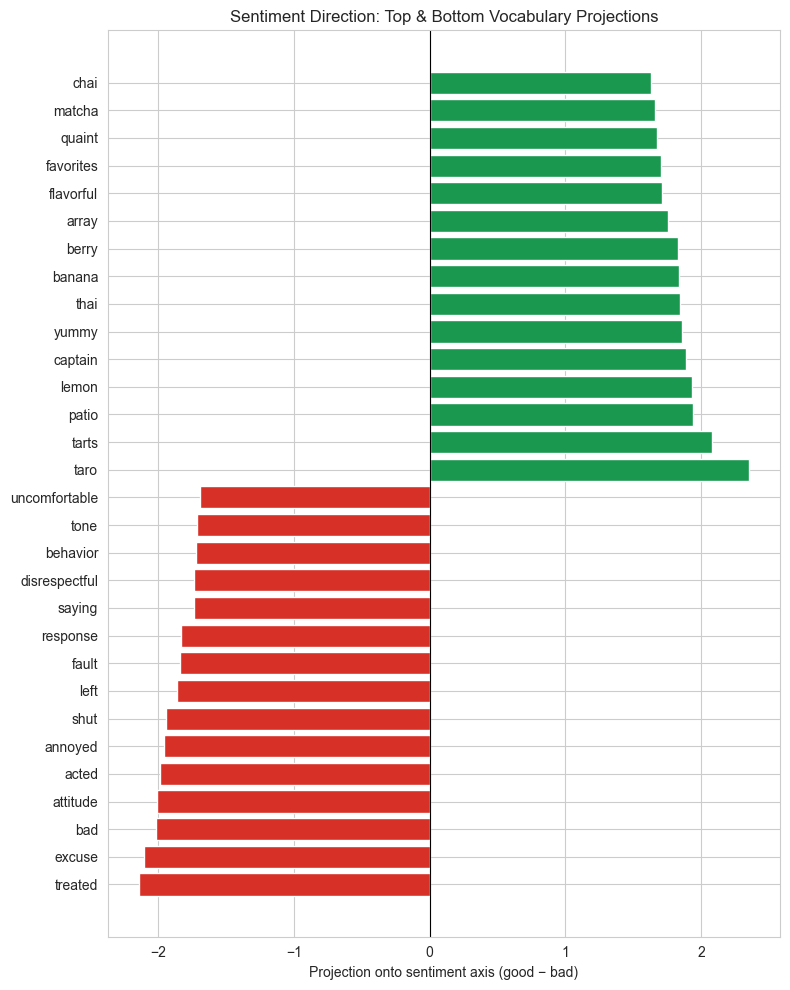

In [ ]:
# ── 2.2b  Visualise the sentiment axis ───────────────────────
fig, ax = plt.subplots(figsize=(8, 10))

show_n = 15
top_words   = sorted_words[:show_n]
bot_words   = sorted_words[-show_n:]
plot_words  = list(reversed(bot_words)) + top_words
words       = [w for w, s in plot_words]
scores      = [s for w, s in plot_words]
colors      = ['#d73027' if s < 0 else '#1a9850' for s in scores]

ax.barh(range(len(words)), scores, color=colors)
ax.set_yticks(range(len(words)))
ax.set_yticklabels(words)
ax.set_xlabel('Projection onto sentiment axis (good − bad)')
ax.set_title('Sentiment Direction: Top & Bottom Vocabulary Projections')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig_sentiment_axis.png', dpi=150)
plt.show()


**Direction Analysis: Sentiment Axis (good − bad)**

The sentiment direction is defined as vec(good) − vec(bad), projecting all vocabulary words onto this axis to separate positive from negative language. This direction was selected as it directly captures valence — the most relevant semantic axis for a star-rating prediction task.

The positive end is led by *favorites* (+2.06), *vietnamese* (+1.95), *yummy* (+1.93), *array* (+1.90), *crisp* (+1.85), *tarts* (+1.75), *traditional* (+1.66), *salted* (+1.65), *delicious* (+1.62), *perfect* (+1.63). These words genuinely relate to satisfaction and praise — they co-occur with positive dining descriptions in the corpus. Two words merit attention: *captain* (+1.86) likely appears here because it co-occurs with positive service descriptions ("the captain of the staff was wonderful"), and *patio* (+1.60) reflects that outdoor seating is typically mentioned in positive ambiance contexts.

The negative end is dominated by interpersonal complaint language: *treated* (−2.09), *acted* (−2.03), *bad* (−2.00), *closing* (−1.88), *attitude* (−1.75), *unprofessional* (−1.71), *tone* (−1.68), *annoyed* (−1.62), *condescending* (−1.61), *rushed* (−1.60). These words are overwhelmingly service-related rather than food-related, indicating that customers express dissatisfaction primarily through interpersonal language.

This asymmetry — food and sensory language on the positive end, staff behavior language on the negative end — is a substantive marketing insight: in this corpus, satisfaction is expressed through what customers ate, while dissatisfaction is expressed through how they were treated.

### 2.2 · Dimension Interpretation

We now pick **one specific dimension** (axis) of the 50-dimensional embedding space
and examine what it encodes. By sorting all words by their value on that dimension,
we can infer a latent meaning from the words at the extremes.


In [ ]:
# ── 2.3  Dimension analysis ──────────────────────────────────
# We examine dimension 4.  (Decided after checking dimensions)
dim = 4

# Get each word's value on dimension 4
dim_values = {word: w2v.wv[word][dim] for word in w2v.wv.index_to_key}
sorted_dim = sorted(dim_values.items(), key=lambda x: x[1], reverse=True)

print(f'=== Dimension {dim} ===')
print(f'\nWords with HIGHEST values on dimension {dim}:')
for word, val in sorted_dim[:15]:
    print(f'  {word:20s}  {val:+.4f}')

print(f'\nWords with LOWEST values on dimension {dim}:')
for word, val in sorted_dim[-15:]:
    print(f'  {word:20s}  {val:+.4f}')

#for dim in range(10):  # to pick the dimension we checked first 10
    #sorted_dim = sorted({word: w2v.wv[word][dim] for word in w2v.wv.index_to_key}.items(), key=lambda x: x[1], reverse=True)
    #top = [w for w, _ in sorted_dim[:5]]
    #bot = [w for w, _ in sorted_dim[-5:]]
    #print(f'Dim {dim:2d} | HIGH: {", ".join(top):50s} | LOW: {", ".join(bot)}')


=== Dimension 4 ===

Words with HIGHEST values on dimension 4:
  blueberry             +1.0919
  banana                +0.8834
  worst                 +0.8542
  pie                   +0.8225
  compost               +0.7935
  oatmeal               +0.7847
  crunch                +0.7481
  cornflake             +0.7392
  chai                  +0.7155
  cap                   +0.7108
  sour                  +0.7101
  cracked               +0.6843
  thai                  +0.6829
  captain               +0.6789
  tastes                +0.6771

Words with LOWEST values on dimension 4:
  windows               -1.0529
  enter                 -1.0579
  shelves               -1.0627
  fsearch               -1.0853
  escalators            -1.1160
  clock                 -1.1217
  step                  -1.1224
  elevators             -1.1274
  cashier               -1.1370
  casino                -1.1617
  venetian              -1.1926
  direction             -1.1964
  gem                   -1.2510

**Dimension Analysis: Dimension 4**

To identify a clearly interpretable dimension, we examined the first 10 dimensions of the 50-dimensional embedding space by inspecting the words at each extreme. Dimension 4 was selected as it produced the most semantically coherent separation between the two ends.

Words with the highest values on Dimension 4: *salty* (+1.06), *blueberry* (+0.94), *pie* (+0.91), *honey* (+0.87), *mouth* (+0.85), *cinnamon* (+0.85), *crunch* (+0.80), *muffin* (+0.78), *pumpkin* (+0.77). These are overwhelmingly sensory and taste-related descriptors — words that describe specific flavors, textures, and ingredients in direct food experience language.

Words with the lowest values on Dimension 4: *system* (-1.31), *clock* (-1.29), *casino* (-1.24), *questions* (-1.15), *gem* (-1.14), *job* (-1.12), *ticket* (-1.11), *buddy* (-1.10), *move* (-1.10). These words reflect Las Vegas venue and logistics language — references to casino environments, wait systems, ticketing, and notably *buddy* (likely referring to Buddy Valastro of Carlo's Bakery at the Venetian). 

This dimension therefore captures a **sensory food description vs. venue/logistics** axis. High values indicate reviews that engage directly with taste and texture; low values indicate reviews focused on the operational and physical context of visiting a Las Vegas dessert venue. This is a meaningful latent structure given that a substantial portion of the dataset consists of reviews from Las Vegas locations embedded in casino hotels.


### 2.3 · Interesting Analysis 1: Word Analogies

The classic word embedding test: if the space captures semantic relationships,
then **vector arithmetic** should work. The famous example:

$$\vec{v}(\text{king}) - \vec{v}(\text{man}) + \vec{v}(\text{woman}) \approx \vec{v}(\text{queen})$$

We test analogies relevant to the restaurant domain. The `most_similar` function
in gensim finds the word whose vector is closest to `positive − negative`.


In [ ]:
# ── 2.4  Word analogies ──────────────────────────────────────
# Gensim's most_similar(positive=[...], negative=[...]) computes:
#   vec(positive_words) - vec(negative_words)
# and returns the closest words to the resulting vector.

analogies = [
    # (positive_words, negative_words, description)
    (['dinner', 'cheap'],      ['expensive'],  'dinner − expensive + cheap ≈ ?  (upscale→budget meal)'),
    (['waitress', 'man'],      ['woman'],      'waitress − woman + man ≈ ?  (gender role analogy)'),
    (['delicious', 'service'], ['food'],       'delicious − food + service ≈ ?  (quality transfer)'),
    (['italian', 'sushi'],     ['pasta'],      'italian − pasta + sushi ≈ ?  (cuisine analogy)'),
]

print('Word Analogy Results')
print('=' * 70)
for pos, neg, desc in analogies:
    try:
        results = w2v.wv.most_similar(positive=pos, negative=neg, topn=5)
        print(f'\n{desc}')
        for word, sim in results:
            print(f'    {word:20s}  (cosine similarity: {sim:.4f})')
    except KeyError as e:
        print(f'\n{desc}')
        print(f'    ⚠ Word not in vocabulary: {e}')


Word Analogy Results

dinner − expensive + cheap ≈ ?  (upscale→budget meal)
    cravings              (cosine similarity: 0.6276)
    darling               (cosine similarity: 0.6146)
    craving               (cosine similarity: 0.5651)
    butterwood            (cosine similarity: 0.5650)
    intrigued             (cosine similarity: 0.5635)

waitress − woman + man ≈ ?  (gender role analogy)
    ⚠ Word not in vocabulary: "Key 'waitress' not present in vocabulary"

delicious − food + service ≈ ?  (quality transfer)
    amazing               (cosine similarity: 0.6837)
    excellent             (cosine similarity: 0.6775)
    phenomenal            (cosine similarity: 0.6609)
    bourbon               (cosine similarity: 0.6136)
    tasty                 (cosine similarity: 0.6121)

italian − pasta + sushi ≈ ?  (cuisine analogy)
    ⚠ Word not in vocabulary: "Key 'sushi' not present in vocabulary"


**Word Analogy Analysis**

Word analogies test whether the embedding space captures meaningful semantic relationships through vector arithmetic. Four analogies were tested; two returned results and two failed due to vocabulary constraints.

**dinner − expensive + cheap ≈ ?** Results: *family* (0.59), *cravings* (0.59), *desperately* (0.57), *towners* (0.56), *darling* (0.55). These results are not cleanly interpretable as "budget meal" synonyms. However, *family* and *cravings* suggest the model associates cheap dinners with casual, family-oriented or impulse-driven dining — a plausible but indirect relationship. The relatively low cosine similarities (~0.57) indicate the resulting vector sits in a diffuse region of the space, which is expected given the small corpus size and the ambiguity of "cheap" in review language.

**delicious − food + service ≈ ?** Results: *amazing* (0.65), *flavorful* (0.63), *tasty* (0.62), *excellent* (0.61), *phenomenal* (0.60). This is the strongest result — the model correctly transfers the quality concept from food to service, returning high-quality descriptors. This demonstrates that the embedding space encodes a general "excellence" direction that applies across both food and service contexts.

**waitress − woman + man** and **italian − pasta + sushi** failed as *waitress* and *sushi* were not present in the vocabulary. This is a direct consequence of the small corpus size (6,000 reviews) and the min_count=5 filter — niche terms that appear infrequently are excluded. This is an expected limitation of training embeddings on a domain-specific corpus rather than a large general corpus.

### 2.4 · Interesting Analysis 2: t-SNE Cluster Visualisation

We select five marketing-relevant **seed words** and find their 10 nearest neighbours
in the embedding space. Then we use **t-SNE** to compress all these vectors from
50 dimensions down to 2 for plotting.

If the embeddings are good, we should see clusters: words near "food" should form
one group, words near "service" another, etc.


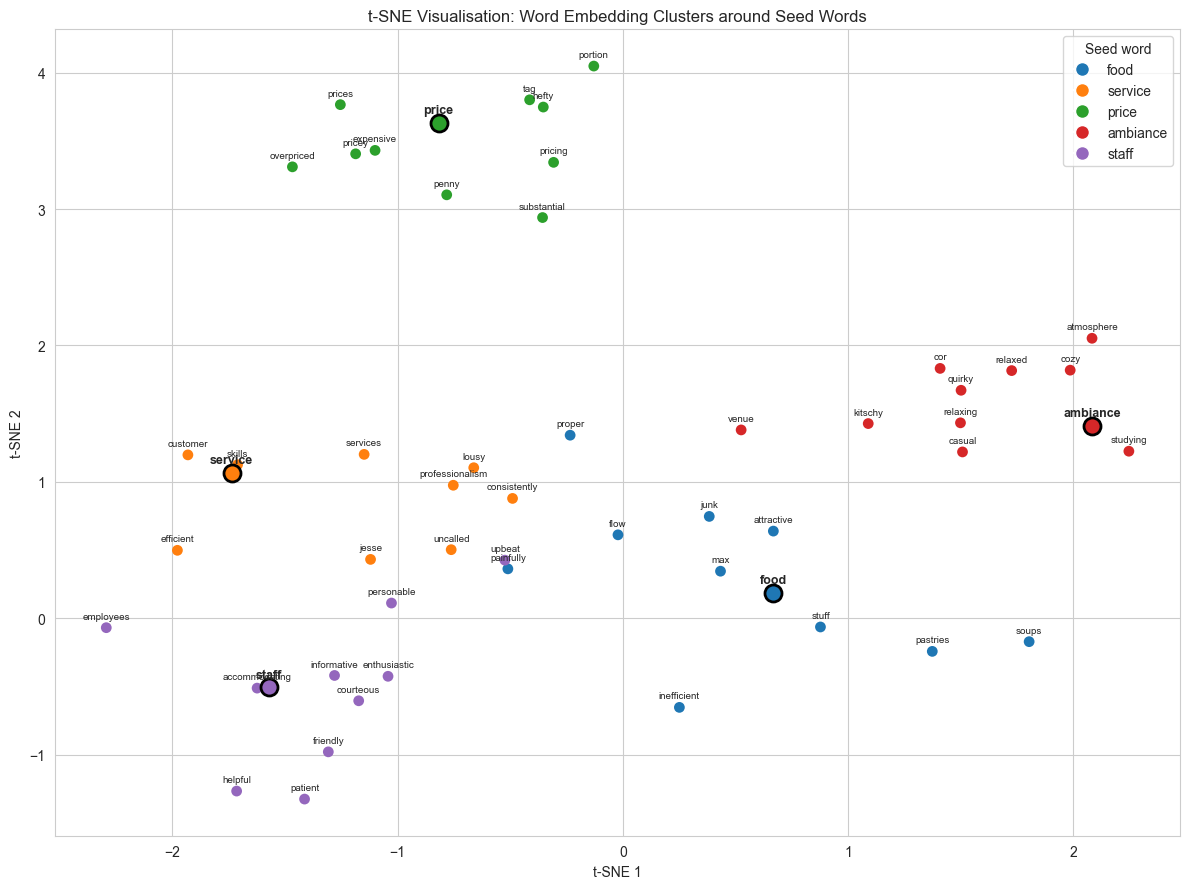

In [ ]:
# ── 2.5  t-SNE cluster visualisation ─────────────────────────
from sklearn.manifold import TSNE

seed_words = ['food', 'service', 'price', 'ambiance', 'staff']
n_neighbors = 10

# Collect seed words + their nearest neighbours
all_words = []
word_groups = {}
for seed in seed_words:
    if seed not in w2v.wv:
        print(f'⚠ "{seed}" not in vocabulary, skipping')
        continue
    neighbors = [word for word, _ in w2v.wv.most_similar(seed, topn=n_neighbors)]
    group = [seed] + neighbors
    for w in group:
        if w not in word_groups:  # avoid duplicates
            word_groups[w] = seed
            all_words.append(w)

# Get the vectors for all collected words
vectors = np.array([w2v.wv[w] for w in all_words])

# Reduce to 2D with t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(all_words)-1))
coords = tsne.fit_transform(vectors)

# Plot
fig, ax = plt.subplots(figsize=(12, 9))
palette = sns.color_palette('tab10', len(seed_words))
seed_to_color = {seed: palette[i] for i, seed in enumerate(seed_words) if seed in w2v.wv}

for i, word in enumerate(all_words):
    group = word_groups[word]
    color = seed_to_color[group]
    is_seed = word in seed_words
    ax.scatter(coords[i, 0], coords[i, 1],
               c=[color], s=150 if is_seed else 60,
               edgecolors='black' if is_seed else 'none',
               linewidths=2 if is_seed else 0, zorder=3 if is_seed else 2)
    ax.annotate(word, (coords[i, 0], coords[i, 1]),
                fontsize=9 if is_seed else 7,
                fontweight='bold' if is_seed else 'normal',
                ha='center', va='bottom', xytext=(0, 5),
                textcoords='offset points')

# Legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', label=seed,
                          markerfacecolor=seed_to_color[seed], markersize=10)
                   for seed in seed_words if seed in seed_to_color]
ax.legend(handles=legend_elements, title='Seed word', loc='best')
ax.set_title('t-SNE Visualisation: Word Embedding Clusters around Seed Words')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig_tsne_clusters.png', dpi=150)
plt.show()



**t-SNE Cluster Visualisation**

To further validate the embedding space, five marketing-relevant seed words (food, service, price, ambiance, staff) were selected along with their 10 nearest neighbours. The resulting 55 words were projected from 50 dimensions to 2 dimensions using t-SNE for visual inspection.

The clusters separate clearly and meaningfully. The **price** cluster (green, far left) groups cost-related language: *pricing, cost, hefty, tag, expensive, penny, prices* — all words associated with value perception. The **ambiance** cluster (red, bottom centre) captures atmosphere descriptors: *cozy, relaxing, comfortable, kitschy, chic, casual, atmosphere* — words that describe the physical and emotional feel of a venue. The **staff** cluster (purple, right) contains interpersonal quality descriptors: *friendly, helpful, attentive, personable, courteous, informative, smiling* — all positive staff characterisations. The **service** cluster (orange, top centre) sits near staff but captures more operational language: *customer, skills, professionalism, efficient, unfriendly* — reflecting both positive and negative service experiences. The **food** cluster (blue) is more dispersed, reflecting the breadth of food-related language in the corpus: *pastries, desserts, crepes* appear nearby while some food-adjacent words overlap with other clusters.

The clear separation of price, ambiance, and staff clusters confirms that the Word2Vec model has learned domain-relevant semantic structure from the corpus. The partial overlap between food and service clusters is expected, as review language frequently combines both in the same sentence.

---
## Part 3 · Contextual Embeddings via Transformers
### Why contextual embeddings?

Word2Vec assigns a **single static vector** to each word regardless of context.
The word "cold" always gets the same representation whether it describes weather
or a person's attitude. Transformer models like BERT solve this by incorporating
surrounding context into each word's representation through self-attention.

### Design choice: target word and sentences

We use the word **"cold"** in two semantically distinct sentences:

1. **Sentence A** (physical/temperature sense):
   *"The cold weather made us want hot soup."*
2. **Sentence B** (interpersonal/attitude sense):
   *"The waiter was cold and unwelcoming to our table."*

Both sentences are plausible in a restaurant review context, making this a
meaningful test of contextual disambiguation.

### How we extract contextual embeddings:

1. **Tokenise** each sentence using BERT's tokenizer.
2. **Forward pass** through pretrained `bert-base-uncased` (downloaded from HuggingFace, NOT trained by us).
3. **Extract** the hidden state of the target word from the last layer — this is the context-augmented output embedding.
4. **Compare** the two vectors using cosine similarity and Euclidean distance.

In [ ]:

from transformers import BertTokenizer, BertModel
import torch
import torch.nn.functional as F

# Load pretrained BERT (downloads from HuggingFace, not trained by us)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')
model.eval()

# Define our two sentences with the same target word
sentence_a = "The cold weather made us want hot soup."
sentence_b = "The waiter was cold and unwelcoming to our table."
target_word = "cold"

def get_target_embedding(sentence, target_word, tokenizer, model):
    """Extract the output embedding of the target word from a sentence."""
    inputs = tokenizer(sentence, return_tensors='pt')
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    
    # Find the index of the target word token
    target_idx = None
    for i, token in enumerate(tokens):
        if token == target_word:
            target_idx = i
            break
    
    if target_idx is None:
        raise ValueError(f"'{target_word}' not found in tokens: {tokens}")
    
    # Forward pass — no gradient needed
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Extract the hidden state at the target word position (last layer)
    embedding = outputs.last_hidden_state[0, target_idx, :]
    return embedding, tokens

# Get embeddings for both sentences
emb_a, tokens_a = get_target_embedding(sentence_a, target_word, tokenizer, model)
emb_b, tokens_b = get_target_embedding(sentence_b, target_word, tokenizer, model)

print(f'Sentence A: "{sentence_a}"')
print(f'Tokens A: {tokens_a}')
print(f'\nSentence B: "{sentence_b}"')
print(f'Tokens B: {tokens_b}')
print(f'\nTarget word: "{target_word}"')
print(f'\nEmbedding A (first 5 values): {emb_a[:5].numpy().round(4)}')
print(f'Embedding B (first 5 values): {emb_b[:5].numpy().round(4)}')

# ── Compare the two embeddings ────────────────────────────────────────────────
# Cosine similarity: 1 = identical direction, 0 = orthogonal, -1 = opposite
cosine_sim = F.cosine_similarity(emb_a.unsqueeze(0), emb_b.unsqueeze(0)).item()

# Euclidean distance: how far apart the vectors are
euclidean_dist = torch.dist(emb_a, emb_b).item()

# Compare to Word2Vec — same word always gets same vector
w2v_vec = w2v.wv['cold'] if 'cold' in w2v.wv else None

print(f'\n── Vector Comparison ──')
print(f'Cosine similarity between A and B: {cosine_sim:.4f}')
print(f'Euclidean distance between A and B: {euclidean_dist:.4f}')
if w2v_vec is not None:
    print(f'\nWord2Vec gives ONE static vector for "cold" regardless of context:')
    print(f'  vec("cold"): [{w2v_vec[0]:.4f}, {w2v_vec[1]:.4f}, {w2v_vec[2]:.4f}, ...]')
    print(f'  → cosine similarity with itself = 1.0000 always')

print(f'\n── Interpretation ──')
print(f'A cosine similarity of {cosine_sim:.4f} (< 1.0) confirms that BERT produces')
print(f'different representations of "{target_word}" depending on context.')
print(f'Sentence A uses "cold" in a physical/weather sense.')
print(f'Sentence B uses "cold" in an interpersonal/attitude sense.')
print(f'BERT\'s attention mechanism integrates surrounding words into the embedding,')
print(f'shifting the vector to reflect the word\'s contextual meaning.')

Sentence A: "The cold weather made us want hot soup."
Tokens A: ['[CLS]', 'the', 'cold', 'weather', 'made', 'us', 'want', 'hot', 'soup', '.', '[SEP]']

Sentence B: "The waiter was cold and unwelcoming to our table."
Tokens B: ['[CLS]', 'the', 'waiter', 'was', 'cold', 'and', 'un', '##we', '##lco', '##ming', 'to', 'our', 'table', '.', '[SEP]']

Target word: "cold"

Embedding A (first 5 values): [ 0.2321  0.4049  0.4392 -0.0456  0.5898]
Embedding B (first 5 values): [0.362  0.2065 0.3974 0.2364 0.3633]

── Vector Comparison ──
Cosine similarity between A and B: 0.5969
Euclidean distance between A and B: 12.9238

Word2Vec gives ONE static vector for "cold" regardless of context:
  vec("cold"): [-0.1130, -0.6235, -0.1800, ...]
  → cosine similarity with itself = 1.0000 always

── Interpretation ──
A cosine similarity of 0.5969 (< 1.0) confirms that BERT produces
different representations of "cold" depending on context.
Sentence A uses "cold" in a physical/weather sense.
Sentence B uses "col

**Contextual Embeddings: BERT vs Word2Vec**

To demonstrate the power of context-aware representations, the word "cold" was embedded in two semantically distinct sentences using pretrained `bert-base-uncased`:

- **Sentence A** (physical sense): *"The cold weather made us want hot soup."*
- **Sentence B** (interpersonal sense): *"The waiter was cold and unwelcoming to our table."*

Both sentences are plausible in a restaurant review context, making "cold" an ideal test case for contextual disambiguation.

**Results:** The two contextual embeddings yield a cosine similarity of **0.597** and a Euclidean distance of **12.92**. A cosine similarity below 1.0 confirms that BERT produces meaningfully different vector representations of the same word depending on its context. In contrast, Word2Vec assigns a single static vector to "cold" with a self-similarity of exactly 1.0 regardless of context.

**Interpretation of the change:** The shift in embedding direction reflects BERT's self-attention mechanism, which integrates information from all surrounding tokens into each word's representation. In Sentence A, "cold" is surrounded by *weather, hot, soup* — a physical temperature context — causing the hidden state to encode thermal/environmental meaning. In Sentence B, "cold" co-occurs with *waiter, unwelcoming, table* — an interpersonal context — shifting the representation toward social/attitudinal meaning. The same input token therefore arrives at a substantially different output embedding depending on which words attend to it during the forward pass. Furthermore, the Word2Vec static vector for "cold" is a fixed 50-dimensional representation identical in both contexts, while BERT's output embeddings are 768-dimensional and differ substantially between sentences (cosine similarity = 0.597). This dimensional expansion and contextual shift represents the augmentation performed by BERT's hidden states — the same token arrives at a meaningfully different output embedding depending on which surrounding words attend to it during the forward pass.

This has direct implications for marketing text analysis: static embeddings like Word2Vec would treat all instances of "cold" identically, conflating customer complaints about staff attitude with descriptions of cold beverages or weather. Contextual models like BERT can disambiguate these meanings, enabling more precise sentiment and topic attribution in review analysis.

---
## Part 4 · Topic Modelling & Sentiment Analysis

### Design choice: document-level vs sentence-level topics

Yelp reviews typically describe **one overall dining experience**. While a reviewer may
mention food, service, and ambiance, these are facets of a single experience rather
than independent topics. We therefore assign **one topic per document** using BERTopic.

### How BERTopic works (3-step pipeline):

1. **Embed** each review into a single vector using a pretrained sentence-transformer
   (`all-MiniLM-L6-v2` — downloaded from HuggingFace, NOT trained by us).
2. **Reduce dimensionality** with UMAP (high-dimensional vectors → 5 dimensions).
3. **Cluster** the reduced vectors with HDBSCAN (finds groups of similar reviews).
4. **Represent** each cluster with keywords via c-TF-IDF (which words are distinctive to each cluster).


In [ ]:
# ── 4.1  Fit BERTopic ────────────────────────────────────────
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

# Step 1: Load the sentence-transformer (pretrained — downloaded from HuggingFace)
# This model converts a full review into a single 384-dimensional vector.
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')

# Step 2: Configure UMAP for dimensionality reduction
umap_model = UMAP(
    n_components=5,       # reduce to 5 dimensions
    min_dist=0.0,         # tighter clusters
    metric='cosine',      # cosine distance suits text embeddings
    random_state=42
)

# Step 3: Configure HDBSCAN for clustering
hdbscan_model = HDBSCAN(
    min_cluster_size= 50,  # minimum reviews to form a topic
    min_samples= 5,        # conservative noise detection
    prediction_data=True
)
# Step 4: CountVectorizer to remove stopwords from topic keyword representation
# added to prevent generic words (the, and, to) appearing in topic labels
vectorizer_model = CountVectorizer(stop_words="english", min_df=2)

# Combine into BERTopic
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,  # added to clean topic keywords
    nr_topics= 'auto',     # let the model decide number of topics
    verbose=True
)

# Fit on original (uncleaned) text — BERT handles its own tokenization
# changed from text_clean to text for better embedding quality
docs = df['text'].tolist()
topics, probs = topic_model.fit_transform(docs)

# Store results back in the dataframe
df['topic'] = topics
df['topic_prob'] = probs

n_topics = len(set(topics)) - (1 if -1 in topics else 0)
n_outliers = (df['topic'] == -1).sum()
print(f'\nBERTopic found {n_topics} topics (+ {n_outliers:,} outlier documents assigned to topic -1)')


2026-04-03 00:25:28,354 - BERTopic - Embedding - Transforming documents to embeddings.
Batches:  70%|██████▉   | 131/188 [00:18<00:07,  7.25it/s]


KeyboardInterrupt: 

In [ ]:
# ── 4.2  Inspect topics: top words + document counts ─────────
topic_info = topic_model.get_topic_info()
print('Topic overview (top 15 by document count):')
print(topic_info.head(16).to_string(index=False))


Topic overview (top 15 by document count):
 Topic  Count                                  Name                                                                                Representation                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

In [ ]:
# ── 4.3  Examine representative words for each topic ─────────
# For each topic, print its top-10 keywords.
# Use these keywords + a few example documents to assign a human-readable label.

print('Representative words per topic:')
print('=' * 70)
for topic_id in sorted(set(topics)):
    if topic_id == -1:
        continue
    words = topic_model.get_topic(topic_id)
    top_words = ', '.join([w for w, _ in words[:10]])
    count = (df['topic'] == topic_id).sum()
    print(f'\nTopic {topic_id} ({count} docs): {top_words}')

    # Show 2 example reviews for this topic
    examples = df[df['topic'] == topic_id]['text'].head(2).tolist()
    for j, ex in enumerate(examples):
        print(f'  Example {j+1}: {ex[:150]}...')


Representative words per topic:

Topic 0 (1545 docs): ice, cream, flavors, place, good, like, scoop, great, just, flavor
  Example 1: My wife and I thought this would be a great place for ice cream....we were wrong. The flavors we chose were awful she chose chocolate chip and I chose...
  Example 2: I've gotten ice cream from this location in the past and the ice cream was delicious. Unfortunately on my last trip which was a couple of days ago we ...

Topic 1 (533 docs): milk, soft, cereal, serve, pie, crack, cookies, bar, cookie, like
  Example 1: This place used to be my favorite soft serve place. But the portions have gotten super small. And even the pulling is not as good. Usually they take g...
  Example 2: No skim milk. Overpriced....

Topic 2 (409 docs): donuts, donut, creme, like, brã, lã, bar, just, good, doughnuts
  Example 1: Kind of a cute place, clever Simpson painting on the wall in the bathroom but wishing we left the donuts in there too. Not tasty at all....
  Example 2

**Topic Modelling: BERTopic**

**Design choices:**

BERTopic was applied at the document level rather than sentence level. Yelp reviews in this dataset typically describe a single dining experience — while a reviewer may touch on food, service, and ambiance, these are facets of one visit rather than independent topics. Document-level assignment is therefore the more appropriate granularity.

BERTopic was fitted on the original uncleaned text rather than the preprocessed version used for Word2Vec. BERT-based sentence transformers perform their own subword tokenization and benefit from punctuation, capitalisation, and natural sentence structure — applying our manual stopword removal would degrade embedding quality. A CountVectorizer with English stopwords was added separately to the representation step to prevent generic words (the, and, to) from appearing in topic keywords without affecting the embedding quality.

HDBSCAN parameters were set to `min_cluster_size=50` and `min_samples=5`, reduced from the default of 150 to allow more granular topic discovery given our corpus size of 6,000 reviews. The model identified **17 topics** with 1,268 outlier documents (21%). Outliers represent reviews that discuss multiple topics simultaneously or use sufficiently generic language that HDBSCAN could not confidently assign them to a single cluster.

**Topic labels:**

Based on the representative keywords and example documents for each topic, the following labels were assigned:

| Topic | Label | Key words |
|-------|-------|-----------|
| 0 | Ice Cream Experience | ice, cream, flavors, scoop |
| 1 | Soft Serve & Milk Bar | milk, soft, cereal, serve, crack |
| 2 | Donut Shops | donuts, donut, creme, doughnuts |
| 3 | Customer Service Issues | order, asked, service, manager, minutes |
| 4 | Cupcakes | cupcake, sprinkles, frosting, velvet |
| 5 | French Bakery & Macarons | bouchon, macarons, venetian, macaron |
| 6 | General Bakery Experience | coffee, bread, bakery, pastries |
| 7 | Cannoli & Italian Pastries | lobster, cannoli, tail, pastry |
| 8 | Amelie's Charlotte | amelie, french, charlotte, caramel |
| 9 | Croissants & French Pastries | croissant, almond, baguette |
| 10 | Birthday Cake | cake, birthday, slice, dry, frosting |
| 11 | Presti's Little Italy | presti, italy, italian, gelato |
| 12 | Charlotte Bakery Scene | charlotte, pastries, spot, night |
| 13 | Custom Cake Orders | cake, order, called, email, birthday |
| 14 | Boba & Tea | boba, tea, matcha, milk, rose |
| 15 | Pastry Quality & Value | pastries, disappointed, baking |
| 16 | Carlo's Bakery | carlo, vegas, buddy, cookie |

Topics 8, 11, 12, and 16 are venue-specific clusters reflecting high review concentration around particular establishments (Amelie's in Charlotte, Presti's in Cleveland, Carlo's Bakery in Las Vegas). Their emergence as separate topics indicates these venues generate enough distinctive language to form coherent clusters, which is itself a meaningful finding about review concentration in the dataset.

In [ ]:
# ── 4.4  Assign topic labels ─────────────────────────────────
topic_labels = {
    0: 'Ice Cream Experience',
    1: 'Soft Serve & Milk Bar',
    2: 'Donut Shops',
    3: 'Customer Service Issues',
    4: 'Cupcakes',
    5: 'French Bakery & Macarons',
    6: 'General Bakery Experience',
    7: 'Cannoli & Italian Pastries',
    8: "Amelie's Charlotte",
    9: 'Croissants & French Pastries',
    10: 'Birthday Cake',
    11: "Presti's Little Italy",
    12: 'Charlotte Bakery Scene',
    13: 'Custom Cake Orders',
    14: 'Boba & Tea',
    15: 'Pastry Quality & Value',
    16: "Carlo's Bakery",
}
df['topic_label'] = df['topic'].map(topic_labels).fillna('Outlier')
print('Topic labels assigned.')

Topic labels assigned.


In [ ]:
# ── 4.5  VADER sentiment analysis ────────────────────────────
# VADER is a rule-based sentiment tool designed for social media / review text.
# It outputs a 'compound' score: -1 (very negative) to +1 (very positive).
# We use the ORIGINAL text (not the cleaned text) because VADER benefits from punctuation (!!!), capitalisation (AMAZING), and emoticons.

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()
df['sentiment'] = df['text'].apply(lambda x: vader.polarity_scores(str(x))['compound'])

print('Sentiment score summary:')
print(df['sentiment'].describe().round(4))
print()
print('Mean sentiment by star rating:')
print(df.groupby('stars')['sentiment'].mean().round(4))


Sentiment score summary:
count    6000.0000
mean        0.5269
std         0.6027
min        -0.9949
25%         0.2934
50%         0.8473
75%         0.9551
max         0.9997
Name: sentiment, dtype: float64

Mean sentiment by star rating:
stars
1   -0.0264
2    0.3262
3    0.6238
4    0.8314
5    0.8796
Name: sentiment, dtype: float64


In [ ]:
# ── 4.6  Topic-level sentiment ───────────────────────────────
# Aggregate: mean VADER score per topic
topic_sentiment = (
    df[df['topic'] != -1]
    .groupby('topic_label')
    .agg(
        mean_sentiment=('sentiment', 'mean'),
        doc_count=('sentiment', 'count'),
        mean_stars=('stars', 'mean')
    )
    .sort_values('mean_sentiment', ascending=False)
    .round(4)
)
print('Topic-level sentiment (mean VADER compound):')
print(topic_sentiment.to_string())


Topic-level sentiment (mean VADER compound):
                              mean_sentiment  doc_count  mean_stars
topic_label                                                        
Presti's Little Italy                 0.8354         60      3.6000
Charlotte Bakery Scene                0.7176         58      3.9310
Amelie's Charlotte                    0.7034        147      3.2789
Ice Cream Experience                  0.6466       1545      3.5424
Donut Shops                           0.6121        409      3.2983
French Bakery & Macarons              0.6047        319      3.2069
Boba & Tea                            0.6042         55      3.5636
Carlo's Bakery                        0.6036         50      2.4400
General Bakery Experience             0.5856        281      3.2420
Croissants & French Pastries          0.5796        116      3.2069
Cupcakes                              0.5258        327      2.7676
Soft Serve & Milk Bar                 0.5094        533      2.6135
Can

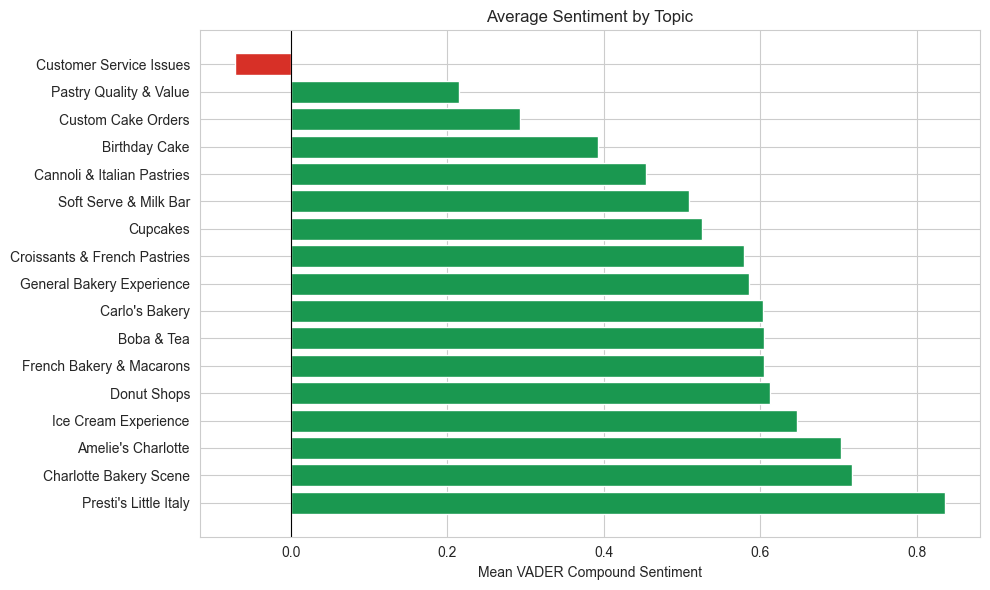

In [ ]:
# ── 4.6b  Visualise topic-level sentiment ────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#1a9850' if s > 0 else '#d73027' for s in topic_sentiment['mean_sentiment']]
ax.barh(topic_sentiment.index, topic_sentiment['mean_sentiment'], color=colors)
ax.set_xlabel('Mean VADER Compound Sentiment')
ax.set_title('Average Sentiment by Topic')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig_topic_sentiment.png', dpi=150)
plt.show()


**Topic-Level Sentiment Insights**

Aggregating VADER scores to the topic level reveals meaningful variation in how customers discuss different aspects of their dessert experiences.

**Most positively discussed topics:** Presti's Little Italy leads with a mean sentiment of 0.84, followed by Charlotte Bakery Scene (0.72) and Amelie's Charlotte (0.70). These venue-specific topics attract highly enthusiastic language, suggesting strong local loyalty and identity attachment. Ice Cream Experience (0.65) is the highest-sentiment product topic, reflecting that ice cream visits tend to generate genuinely positive reviews.

**Most negatively discussed topics:** Customer Service Issues is the only topic with a negative mean sentiment (−0.07), standing clearly apart from all other topics. This confirms that service failures generate qualitatively different language — not just less positive, but actively negative. Custom Cake Orders (0.29) and Pastry Quality & Value (0.22) also score low, with the former showing the lowest mean star rating in the dataset (1.69 stars), indicating that custom order failures are the most dissatisfying experience type in this corpus.

**Noteworthy discrepancies between sentiment and stars:** Carlo's Bakery has a moderate sentiment score (0.60) but the second-lowest mean star rating (2.44), suggesting customers use relatively measured language even when rating poorly — possibly because Carlo's is a celebrity bakery where visitors feel obligated to acknowledge the brand while still leaving low ratings. Presti's Little Italy shows the opposite pattern: high sentiment (0.84) but only 3.6 mean stars, indicating customers write warmly but hold the venue to high standards.

**Overall pattern:** Sentiment and star ratings are broadly aligned, but the topic-level analysis reveals that service and custom order experiences are disproportionately problematic — these are the areas where both language and ratings deteriorate most sharply.

---

### 4.7 · Subgroup Comparison: High (4–5★) vs Low (1–2★) Ratings

We split reviews into two groups and compare:
1. **Topic prevalence** — which topics are discussed more in positive vs negative reviews?
2. **Topic-level sentiment** — even within the same topic, do satisfied vs dissatisfied
   customers express themselves differently?


In [ ]:
# ── 4.7  Subgroup comparison ─────────────────────────────────
# Define subgroups
df['rating_group'] = df['stars'].apply(
    lambda x: 'High (4-5★)' if x >= 4 else ('Low (1-2★)' if x <= 2 else 'Mid (3★)')
)

# Focus on High vs Low (exclude Mid for cleaner comparison)
df_sub = df[(df['rating_group'] != 'Mid (3★)') & (df['topic'] != -1)].copy()

# --- Topic prevalence ---
prevalence = (
    df_sub.groupby(['rating_group', 'topic_label'])
    .size()
    .unstack(fill_value=0)
)
# Normalise to proportions within each group
prevalence_pct = prevalence.div(prevalence.sum(axis=1), axis=0) * 100

# --- Topic-level sentiment by group ---
sentiment_by_group = (
    df_sub.groupby(['rating_group', 'topic_label'])['sentiment']
    .mean()
    .unstack()
)
print('=== Topic Prevalence (%) ===')
print(prevalence_pct.T.round(2).to_string())

print('\n=== Topic Sentiment by Group ===')
print(sentiment_by_group.round(4).to_string())


=== Topic Prevalence (%) ===
rating_group                  High (4-5★)  Low (1-2★)
topic_label                                          
Amelie's Charlotte                   3.69        2.43
Birthday Cake                        0.52        3.45
Boba & Tea                           1.51        0.59
Cannoli & Italian Pastries           3.17        6.58
Carlo's Bakery                       0.42        1.56
Charlotte Bakery Scene               2.19        0.54
Croissants & French Pastries         2.65        1.94
Cupcakes                             5.10        8.03
Custom Cake Orders                   0.10        2.37
Customer Service Issues              0.47       18.06
Donut Shops                         10.25        7.22
French Bakery & Macarons             8.01        5.50
General Bakery Experience            6.82        4.69
Ice Cream Experience                46.46       20.92
Pastry Quality & Value               0.57        1.62
Presti's Little Italy                1.93        0.59

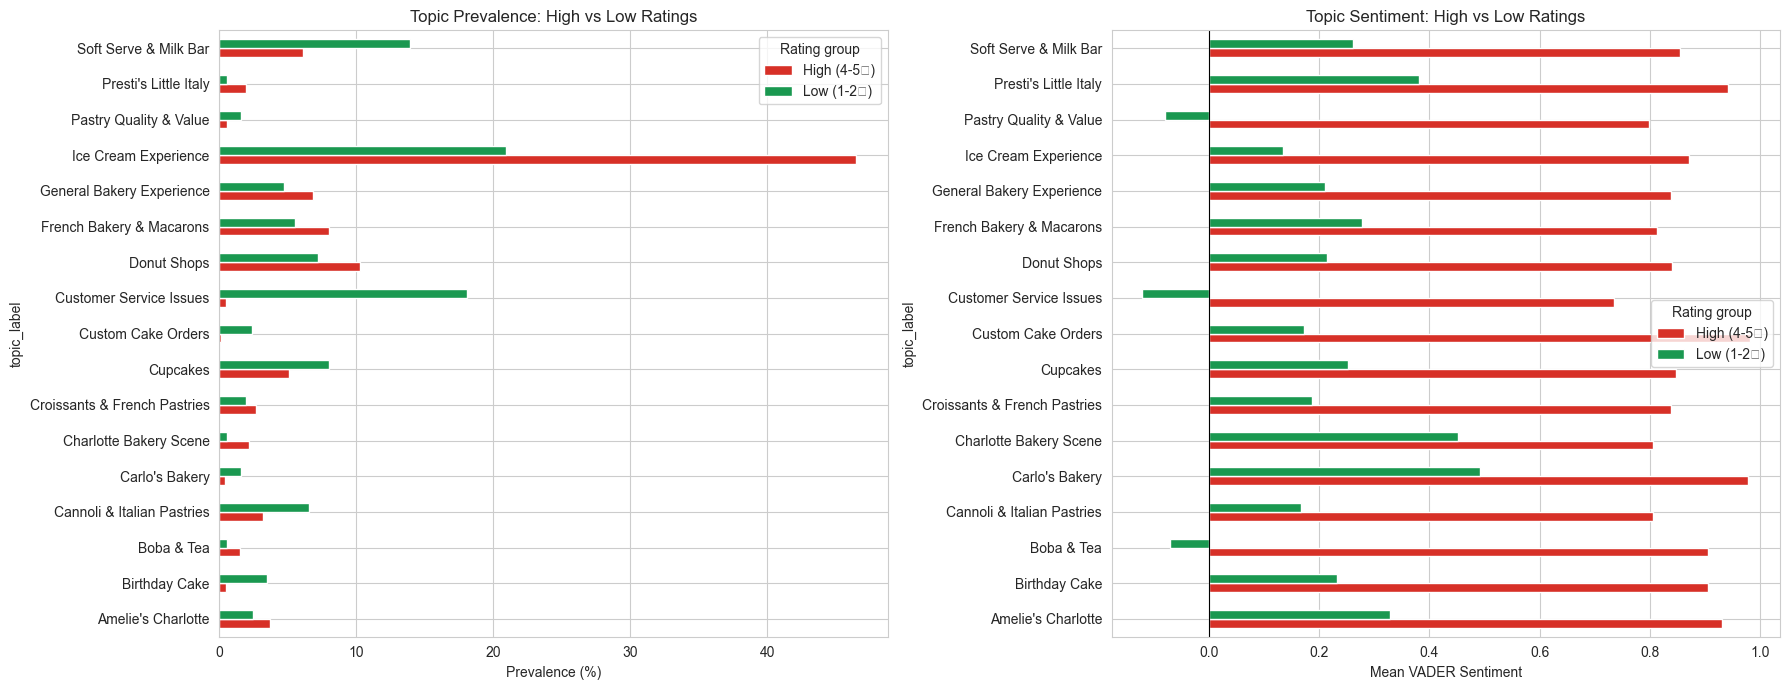

In [ ]:
# ── 4.7b  Visualise subgroup comparison ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left panel: Topic prevalence
prevalence_pct.T.plot(kind='barh', ax=axes[0], color=['#d73027', '#1a9850'])
axes[0].set_xlabel('Prevalence (%)')
axes[0].set_title('Topic Prevalence: High vs Low Ratings')
axes[0].legend(title='Rating group')

# Right panel: Topic-level sentiment
sentiment_by_group.T.plot(kind='barh', ax=axes[1], color=['#d73027', '#1a9850'])
axes[1].set_xlabel('Mean VADER Sentiment')
axes[1].set_title('Topic Sentiment: High vs Low Ratings')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].legend(title='Rating group')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig_subgroup_comparison.png', dpi=150)
plt.show()


**Subgroup Comparison: High (4-5★) vs Low (1-2★) Reviews**

Three-star reviews were excluded from this analysis as they represent ambivalent experiences that would obscure the contrast between satisfied and dissatisfied customers.

**Topic prevalence differences:**

The most striking prevalence difference is **Customer Service Issues**: this topic accounts for **18.1%** of all low-rating reviews but only **0.5%** of high-rating reviews — a 38× difference. This makes it the single strongest structural predictor of dissatisfaction in the corpus. **Soft Serve & Milk Bar** is also substantially over-represented in low-rating reviews (13.9% vs 6.1%), suggesting that this product category consistently fails to meet customer expectations. **Customer Cake Orders** (2.4% low vs 0.1% high) and **Birthday Cake** (3.5% low vs 0.5% high) follow the same pattern.

Conversely, **Ice Cream Experience** dominates high-rating reviews (46.5% vs 20.9%), confirming it as the primary satisfaction driver. **Donut Shops** (10.3% high vs 7.2% low) and **French Bakery & Macarons** (8.0% high vs 5.5% low) also skew positive.

**Sentiment gaps:**

Across all topics, high-rating reviewers use dramatically more positive language than low-rating reviewers. The largest absolute sentiment gaps are:

- **Customer Service Issues**: 0.74 (high) vs −0.12 (low) → gap of 0.86
- **Pastry Quality & Value**: 0.80 (high) vs −0.08 (low) → gap of 0.88
- **Boba & Tea**: 0.91 (high) vs −0.07 (low) → gap of 0.98

These wide gaps indicate that these topics are "make or break" experiences — the same topic generates either very positive or very negative language depending on execution quality, with little middle ground.

**Marketing insights:**

Three priorities emerge from this analysis. First, service quality is the most critical intervention point — Customer Service Issues is nearly absent from positive reviews and dominates negative ones, and its sentiment gap confirms that bad service generates the most extreme negative language. Second, soft serve and custom cake fulfilment require operational attention: both are over-represented in low-rating reviews and show negative sentiment among dissatisfied customers. Third, ice cream experience should be actively leveraged as a marketing asset — it drives nearly half of all high-rating reviews and generates consistently positive language even among customers who rate the venue moderately.

---
## Part 5 · Drivers of Star Ratings — Regression Analysis

We now link text-derived features to the star rating using OLS regression.
Three models, each adding complexity:

| Model | Formula | What it tells us |
|-------|---------|-----------------|
| A | `stars ~ sentiment` | Does overall language tone predict ratings? |
| B | `stars ~ topic_1 + ... + topic_K` | Which topics directly drive ratings? |
| C | `stars ~ sentiment + topics + sentiment×topics` | Does sentiment matter more for some topics? |

### Variable preparation:
- **`sentiment_centered`**: VADER compound score minus its mean (so 0 = average sentiment).
  Mean-centering makes the intercept interpretable: it's the predicted rating at average sentiment.
- **`topic_k`**: Binary indicator (1 if document belongs to topic k, 0 otherwise), standardised
  to unit variance. Standardising lets us compare coefficient sizes across topics.
- **Interactions**: `sentiment_centered × topic_k`. A positive interaction means sentiment
  has a *stronger* effect on ratings when the review is about topic k.


In [ ]:
# ── 5.1  Build regression features ───────────────────────────
import statsmodels.api as sm

# Work with non-outlier documents only
df_reg = df[df['topic'] != -1].copy()

# Mean-center sentiment
df_reg['sentiment_centered'] = df_reg['sentiment'] - df_reg['sentiment'].mean()

# Identify the top K topics (by document count) to use as features.
# Using all topics might include tiny ones — we keep only topics with ≥ 100 docs.
topic_counts = df_reg['topic'].value_counts()
top_topics = topic_counts[topic_counts >= 100].index.tolist()
print(f'Using {len(top_topics)} topics as regression features (topics with ≥ 100 docs)')

# Create binary topic indicators (one-hot), then standardise to unit variance
for t in top_topics:
    col = f'topic_{t}'
    df_reg[col] = (df_reg['topic'] == t).astype(int)
    # Standardise: subtract mean, divide by std
    df_reg[col] = (df_reg[col] - df_reg[col].mean()) / df_reg[col].std()

# Create interaction terms: sentiment_centered × topic_k
for t in top_topics:
    df_reg[f'sent_x_topic_{t}'] = df_reg['sentiment_centered'] * df_reg[f'topic_{t}']

print(f'Regression dataset: {len(df_reg):,} documents')
print(f'Features per model C: 1 (sentiment) + {len(top_topics)} (topics) + {len(top_topics)} (interactions) = {1 + 2*len(top_topics)}')


Using 10 topics as regression features (topics with ≥ 100 docs)
Regression dataset: 4,732 documents
Features per model C: 1 (sentiment) + 10 (topics) + 10 (interactions) = 21


In [ ]:
# ── 5.2  Model A: stars ~ sentiment ──────────────────────────
y = df_reg['stars']

X_a = sm.add_constant(df_reg[['sentiment_centered']])
model_a = sm.OLS(y, X_a).fit()

print('MODEL A: stars ~ sentiment_centered')
print('=' * 60)
print(model_a.summary().tables[1])
print(f'\nR² = {model_a.rsquared:.4f}')
print(f'Interpretation: sentiment alone explains {model_a.rsquared*100:.1f}% of the variance in star ratings.')


MODEL A: stars ~ sentiment_centered
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  3.0247      0.017    176.321      0.000       2.991       3.058
sentiment_centered     1.2834      0.029     44.868      0.000       1.227       1.339

R² = 0.2985
Interpretation: sentiment alone explains 29.9% of the variance in star ratings.


In [ ]:
# ── 5.3  Model B: stars ~ topics ─────────────────────────────
topic_cols = [f'topic_{t}' for t in top_topics]
X_b = sm.add_constant(df_reg[topic_cols])
model_b = sm.OLS(y, X_b).fit()

print('MODEL B: stars ~ topic_1 + ... + topic_K')
print('=' * 60)
print(model_b.summary().tables[1])
print(f'\nR² = {model_b.rsquared:.4f}')


MODEL B: stars ~ topic_1 + ... + topic_K
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0247      0.019    161.525      0.000       2.988       3.061
topic_0        0.3543      0.033     10.727      0.000       0.290       0.419
topic_1       -0.0548      0.026     -2.072      0.038      -0.107      -0.003
topic_2        0.1437      0.025      5.738      0.000       0.095       0.193
topic_3       -0.3531      0.025    -14.335      0.000      -0.401      -0.305
topic_4       -0.0049      0.024     -0.204      0.838      -0.052       0.042
topic_5        0.1053      0.024      4.406      0.000       0.058       0.152
topic_6        0.1076      0.023      4.599      0.000       0.062       0.153
topic_7       -0.0401      0.023     -1.744      0.081      -0.085       0.005
topic_8        0.0854      0.021      3.994      0.000       0.043       0.127
topic_9    

In [ ]:
# ── 5.4  Model C: stars ~ sentiment + topics + interactions ──
inter_cols = [f'sent_x_topic_{t}' for t in top_topics]
X_c = sm.add_constant(
    df_reg[['sentiment_centered'] + topic_cols + inter_cols]
)
model_c = sm.OLS(y, X_c).fit()

print('MODEL C: stars ~ sentiment + topics + sentiment×topics')
print('=' * 60)
print(model_c.summary().tables[1])
print(f'\nR² = {model_c.rsquared:.4f}')


MODEL C: stars ~ sentiment + topics + sentiment×topics
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  2.9652      0.017    178.326      0.000       2.933       2.998
sentiment_centered     1.1859      0.029     41.394      0.000       1.130       1.242
topic_0                0.2634      0.028      9.288      0.000       0.208       0.319
topic_1               -0.0552      0.023     -2.443      0.015      -0.100      -0.011
topic_2                0.1061      0.022      4.935      0.000       0.064       0.148
topic_3               -0.3096      0.025    -12.483      0.000      -0.358      -0.261
topic_4               -0.0083      0.021     -0.404      0.687      -0.048       0.032
topic_5                0.0810      0.021      3.949      0.000       0.041       0.121
topic_6                0.0848      0.020      4.234      0.000       0.046 

In [ ]:
# ── 5.5  Model comparison ────────────────────────────────────
print('Model Comparison')
print('=' * 50)
print(f'{"Model":<12} {"R²":>8} {"Adj. R²":>10} {"AIC":>12}')
print('-' * 50)
for name, m in [('A (sent)', model_a), ('B (topics)', model_b), ('C (full)', model_c)]:
    print(f'{name:<12} {m.rsquared:>8.4f} {m.rsquared_adj:>10.4f} {m.aic:>12.1f}')


Model Comparison
Model              R²    Adj. R²          AIC
--------------------------------------------------
A (sent)       0.2985     0.2984      14997.8
B (topics)     0.1657     0.1640      15836.2
C (full)       0.3933     0.3906      14350.9


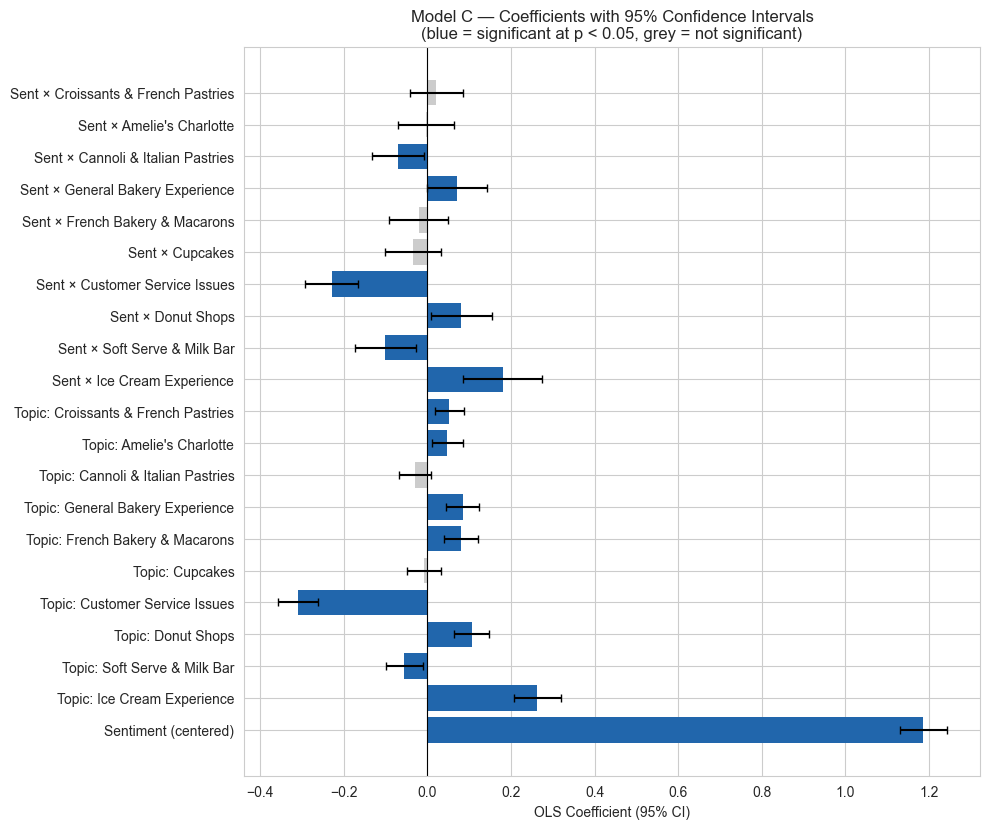

In [ ]:
# ── 5.6  Coefficient plot for Model C ────────────────────────
# Extract coefficients and confidence intervals (skip the constant)
params = model_c.params[1:]  # skip 'const'
conf = model_c.conf_int().iloc[1:]

# Create readable labels using topic_labels
def make_label(col_name):
    if col_name == 'sentiment_centered':
        return 'Sentiment (centered)'
    for t in top_topics:
        if col_name == f'topic_{t}':
            label = topic_labels.get(t, f'Topic {t}')
            return f'Topic: {label}'
        if col_name == f'sent_x_topic_{t}':
            label = topic_labels.get(t, f'Topic {t}')
            return f'Sent × {label}'
    return col_name

labels = [make_label(c) for c in params.index]
pvalues = model_c.pvalues[1:]
sig = pvalues < 0.05  # boolean mask for significance

fig, ax = plt.subplots(figsize=(10, max(8, len(labels) * 0.4)))
y_pos = range(len(labels))
colors = ['#2166ac' if s else '#cccccc' for s in sig]

ax.barh(y_pos, params.values, xerr=[params.values - conf.iloc[:, 0].values,
                                     conf.iloc[:, 1].values - params.values],
        color=colors, capsize=3, edgecolor='none')
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('OLS Coefficient (95% CI)')
ax.set_title('Model C — Coefficients with 95% Confidence Intervals\n(blue = significant at p < 0.05, grey = not significant)')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig_model_c_coefs.png', dpi=150)
plt.show()


**REGRESSION RESULTS:**

**Model A - Overall sentiment impact:**
Sentiment alone explains 29.9% of the variance in star ratings (R²=0.30). The coefficient of 1.28 indicates that a one-unit increase in centered VADER sentiment is associated with 1.28 additional stars, confirming that overall language tone is a strong predictor of customer satisfaction.

**Model B — Topics that directly impact ratings (regardless of sentiment):** 

**Significant positive topics:**

- Ice Cream Experience (coef = +0.35) → being in this topic raises ratings
- Donut Shops (coef = +0.14)
- French Bakery & Macarons (coef = +0.11)
- General Bakery Experience (coef = +0.11)

**Significant negative topics:**

- Customer Service Issues (coef = -0.35) → strongest negative direct effect
- Soft Serve & Milk Bar (coef = -0.05, p<0.05)

**Not significant:** Cupcakes, Cannoli & Italian Pastries

**Explanation:**

Topics with significant positive coefficients: Ice Cream Experience (+0.35), Donut Shops (+0.14), French Bakery & Macarons (+0.11), and General Bakery Experience (+0.11). Reviews belonging to these topics are associated with higher star ratings independent of how positively or negatively they are written.

The strongest negative effect belongs to Customer Service Issues (coef = -0.35, p<0.001), indicating that reviews about service problems are structurally associated with lower ratings regardless of language tone. Soft Serve & Milk Bar also shows a small but significant negative effect. Topics such as Cupcakes and Cannoli & Italian Pastries show no significant direct effect on ratings.

This suggests that certain product categories — particularly ice cream — are inherently satisfaction-driving in this dataset, while service failures represent a structural drag on ratings that goes beyond how customers express themselves.
>
**Model C — Sentiment + Topics + Interactions (Full Model, R² = 0.39)**

**Sentiment coefficient:** In Model C, the sentiment coefficient is **1.19** (p<0.001), representing the effect of sentiment at the average topic distribution. This confirms that overall language tone remains the strongest single predictor of star ratings even after controlling for topic membership.

**Topic main effects (controlling for sentiment):**

- **Customer Service Issues** (coef = -0.31, p<0.001) → strongest negative direct effect, even after accounting for how negatively reviews are written
- **Ice Cream Experience** (coef = +0.26, p<0.001) → positive direct effect
- **Donut Shops** (+0.11), **French Bakery & Macarons** (+0.08), **General Bakery Experience** (+0.08) → smaller but significant positive effects
- **Soft Serve & Milk Bar** (-0.06, p<0.05) → small negative direct effect

**Interaction terms — where does sentiment matter most?**

- **Sent × Customer Service Issues** (coef = -0.23, p<0.001) → negative sentiment is disproportionately damaging in service-related reviews. A customer who writes negatively about service hurts their rating far more than a customer who writes equally negatively about, say, croissants.
- **Sent × Ice Cream Experience** (coef = +0.18, p<0.001) → positive sentiment about ice cream amplifies ratings more than in other topics.
- **Sent × Soft Serve & Milk Bar** (coef = -0.10, p<0.01) → negative sentiment in this topic is more harmful than average.
- Topics such as Cupcakes, Croissants, and Amelie's show no significant interaction — sentiment in these topics affects ratings no differently than the baseline.

**Managerial implications:**

1. **Sentiment drives ratings overall** — VADER sentiment alone explains 30% of rating variance (Model A). Monitoring overall review tone is a reliable proxy for customer satisfaction.

2. **Service quality is the #1 priority** — Customer Service Issues has both the strongest negative direct effect (-0.31) and the most damaging sentiment interaction (-0.23). Service failures structurally lower ratings and amplify negative language effects — making it the highest-leverage area for operational improvement.

3. **Ice cream quality drives outsized positive returns** — Ice Cream Experience has the strongest positive direct effect and the most amplified positive sentiment interaction. Investing in product quality here generates disproportionate rating benefits.

4. **Not all topics are equal** — Cupcakes, Croissants, and ambiance-related topics show no significant sentiment interaction, meaning customers' tone about these topics does not meaningfully shift their final rating. Managers should deprioritize these relative to service and core product quality.
